<a href="https://colab.research.google.com/github/ProjetosGracie/MLAM_GS/blob/main/GS_MLAM_CitizenTech.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Solution – MLAM (CitizenTech)
## Inclusão digital: o que explica o acesso à internet nos países?

**Integrantes:** Conrado Gracie – RM569157 | Renato Sandreschi – RM569156

**Base de dados:** `Final.csv` (cobertura de celular, internet e banda larga por país, 1980–2020). Fonte: ver README.

Problema escolhido (CitizenTech – cidades e comunidades): a inclusão digital. Quais indicadores de infraestrutura de conectividade (telefonia celular e banda larga) estão mais associados à parcela da população que usa internet? Entender isso ajuda governos e empresas a decidir onde investir para reduzir a exclusão digital de comunidades.

```markdown
# Global Solution – MLAM (CitizenTech)
## Inclusão Digital e Modelagem Preditiva com Classificadores

Este notebook apresenta o saneamento, a análise estatística e a modelagem preditiva utilizando classificadores supervisionados para identificar fatores determinantes na inclusão digital global.
```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Algoritmos de classificação
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Warnings (opcional)
import warnings
warnings.filterwarnings('ignore')

# Métricas para modelos de classificação
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report


## 1. Configurações Gerais


In [2]:
URL_BASE = "https://raw.githubusercontent.com/ProjetosGracie/MLAM_GS/1f477a4b45059cc6d6aa0ffcb72213c0c2cdb22b/Final.csv"

# garante resultados reprodutíveis (sorteios e divisão treino/teste)
SEMENTE = 42
# ano escolhido: uma observação por país e boa cobertura de dados
ANO_ANALISE = 2017
# país com "acesso alto" = pelo menos 50% da população usa internet
LIMIAR_ACESSO_ALTO = 50

#Darkviolet
COR_PRINCIPAL = "#9400d3"

#Ghostwhite
COR_DESTAQUE = "#f8f8ff"

# Linhas da base que representam grupos de países (e não países)
NAO_PAISES = ["East Asia and Pacific", "Europe and Central Asia", "European Union", "High income","Latin America and Caribbean", "Low and middle income", "Low income", "Lower middle income","Middle East and North Africa", "Middle income", "North America", "South Asia","Sub-Saharan Africa", "Upper middle income", "World",]

COLUNAS_NUMERICAS = ["Cellular Subscription", "Internet Users(%)", "No. of Internet Users", "Broadband Subscription"]
NOMES_CURTOS = {"Cellular Subscription": "celular","Internet Users(%)": "internet_pct","No. of Internet Users": "usuarios","Broadband Subscription": "banda_larga",}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
print("Configurações carregadas.")


Configurações carregadas.



## 2. FUNÇÕES AUXILIARES 1/3 – DISTRIBUIÇÃO NORMAL E TESTE Z - Implementadas apenas com NumPy


In [3]:
# Função densidade de probabilidade (a "curva do sino") da Normal(mu, sigma)
def densidade_normal(x, mu: float = 0.0, sigma: float = 1.0):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))

# P(X < valor): área sob a curva normal à esquerda de `valor` (regra do trapézio)
def prob_normal_menor_que(valor: float, mu: float = 0.0, sigma: float = 1.0, passos: int = 100_000) -> float:
   # além de 10 desvios padrão a área é praticamente nula
    inicio = mu - 10 * sigma
    if valor <= inicio:
        return 0.0
    xs = np.linspace(inicio, valor, passos)
    ys = densidade_normal(xs, mu, sigma)
    return float(np.sum((ys[1:] + ys[:-1]) / 2 * np.diff(xs)))

In [4]:
# Valor z tal que P(Z < z) = prob, encontrado pelo método da bisseção
def quantil_normal_padrao(prob: float, tolerancia: float = 1e-9) -> float:
    baixo, alto = -10.0, 10.0
    while alto - baixo > tolerancia:
        meio = (baixo + alto) / 2
        if prob_normal_menor_que(meio) < prob:
            baixo = meio
        else:
            alto = meio
    return (baixo + alto) / 2

# Classifica um evento de acordo com sua probabilidade.
def classificar_evento(prob: float) -> str:
    if prob == 0:
        return "evento impossível"
    if prob == 1:
        return "evento certo"
    if round(prob, 4) == 0.5:
        return "evento equiprovável (50%)"
    return "evento provável (p > 0,5)" if prob > 0.5 else "evento improvável (p < 0,5)"

In [5]:
# Teste Z unilateral para a média, usando uma amostra aleatória dos dados.
# Cauda = "menor" -> H1: média < mu_ref  |  cauda = "maior" -> H1: média > mu_ref
def teste_z_unilateral(dados: pd.Series, mu_ref: float, sigma_ref: float,n_amostra: int, alfa: float, cauda: str, semente: int = SEMENTE) -> dict:
    amostra = dados.sample(n=n_amostra, random_state=semente)
    x_barra = amostra.mean()
    z = (x_barra - mu_ref) / (sigma_ref / np.sqrt(n_amostra))

    if cauda == "menor":
        z_crit = quantil_normal_padrao(alfa)
        p_valor = prob_normal_menor_que(z)
        rejeita = z < z_crit
        h1 = f"μ < {mu_ref:.2f}"
    else:
        z_crit = quantil_normal_padrao(1 - alfa)
        p_valor = 1 - prob_normal_menor_que(z)
        rejeita = z > z_crit
        h1 = f"μ > {mu_ref:.2f}"

    return {"n": n_amostra, "alpha": alfa, "cauda": cauda, "h0": f"μ = {mu_ref:.2f}", "h1": h1,
            "xbarra": x_barra, "z": z, "z_crit": z_crit, "p_valor": p_valor, "rejeita": bool(rejeita)}

# Mostra o resultado de um teste Z de forma organizada
def exibir_teste_z(resultado: dict, titulo: str) -> None:
    print(f"=== {titulo} ===")
    print(f"H0: {resultado['h0']}   |   H1: {resultado['h1']}")
    print(f"n = {resultado['n']} | nível de significância = {resultado['alpha']:.0%} "
          f"| média da amostra = {resultado['xbarra']:.4f}")
    print(f"Z calculado = {resultado['z']:.4f} | Z crítico = {resultado['z_crit']:.4f} "
          f"| p-valor = {resultado['p_valor']:.4f}")
    print("DECISÃO:", "REJEITA H0" if resultado["rejeita"] else "NÃO REJEITA H0")


## 3. FUNÇÕES AUXILIARES 2/3 – REGRESSÕES, TESTE F E AVALIAÇÃO DE CLASSIFICADORES

In [6]:
# Regressão linear (simples ou múltipla) por mínimos quadrados.
# Retorna coeficientes [intercepto, b1, b2, ...], valores previstos, R², R² ajustado e estatística F.
def ajustar_regressao_linear(X: pd.DataFrame, y: pd.Series) -> dict:
  # n observações, k variáveis explicativas
    n, k = X.shape
  # coluna de 1s = intercepto
    A = np.column_stack([np.ones(n), X.to_numpy(dtype=float)])
    y_np = y.to_numpy(dtype=float)

    coef, *_ = np.linalg.lstsq(A, y_np, rcond=None)
    previsto = A @ coef

 # erro do modelo
    soma_quad_res = np.sum((y_np - previsto) ** 2)
# variação total de y
    soma_quad_tot = np.sum((y_np - y_np.mean()) ** 2)
    r2 = 1 - soma_quad_res / soma_quad_tot
    r2_ajustado = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    F = (r2 / k) / ((1 - r2) / (n - k - 1))

    return {"coef": coef, "previsto": previsto, "r2": r2, "r2_ajustado": r2_ajustado,"F": F, "gl_num": k, "gl_den": n - k - 1}

# Teste F de significância do modelo, simulando a distribuição F
# Por definição, F = (qui-quadrado_1 / gl1) / (qui-quadrado_2 / gl2)
# Retorna o F crítico (ao nível `nivel`) e o p-valor = proporção de simulações com F simulado >= F calculado.
def teste_f_por_simulacao(F: float, gl_num: int, gl_den: int, nivel: float = 0.05,n_sim: int = 1_000_000, semente: int = SEMENTE) -> dict:
    rng = np.random.default_rng(semente)
    f_simulado = (rng.chisquare(gl_num, n_sim) / gl_num) / (rng.chisquare(gl_den, n_sim) / gl_den)
    return {"F_critico": float(np.quantile(f_simulado, 1 - nivel)),"p_valor": float(np.mean(f_simulado >= F)),"resolucao": 1 / n_sim}

In [7]:
# Escreve o p-valor; se for zero na simulação, informa que é menor que a resolução
def formatar_p(p_valor: float, resolucao: float) -> str:
    return f"< {resolucao:.6f}" if p_valor == 0 else f"{p_valor:.6f}"

# Regressão logística binária ajustada pelo método de Newton-Raphson.
# Internamente as variáveis são padronizadas (convergência estável); no final os coeficientes são convertidos de volta para a escala original, para que a equação use as unidades dos dados.
def ajustar_regressao_logistica(X: pd.DataFrame, y: pd.Series, max_iter: int = 100, tol: float = 1e-9) -> dict:
    X_np, y_np = X.to_numpy(dtype=float), y.to_numpy(dtype=float)
    media, desvio = X_np.mean(axis=0), X_np.std(axis=0)
    Z = np.column_stack([np.ones(len(X_np)), (X_np - media) / desvio])

    beta = np.zeros(Z.shape[1])
    for _ in range(max_iter):
      # probabilidades atuais
        p = 1 / (1 + np.exp(-Z @ beta))
        gradiente = Z.T @ (y_np - p)
        hessiana = Z.T @ (Z * (p * (1 - p))[:, None])
        passo = np.linalg.solve(hessiana, gradiente)
        beta = beta + passo
        if np.max(np.abs(passo)) < tol:
            break
 # volta para a escala original
    coef = beta[1:] / desvio
    intercepto = beta[0] - np.sum(beta[1:] * media / desvio)
    return {"intercepto": intercepto, "coef": coef}

In [8]:
# Probabilidade de a classe ser 1, dada a equação logística ajustada.
def probabilidade_logistica(modelo: dict, X: pd.DataFrame) -> np.ndarray:
    z = modelo["intercepto"] + X.to_numpy(dtype=float) @ modelo["coef"]
    return 1 / (1 + np.exp(-z))

# Reúne as principais métricas de classificação de um modelo.
def avaliar_classificador(nome: str, y_real, y_previsto) -> dict:
    return {"Modelo": nome,"Acurácia": accuracy_score(y_real, y_previsto),"Precisão": precision_score(y_real, y_previsto),"Recall": recall_score(y_real, y_previsto),"F1": f1_score(y_real, y_previsto)}

## 4. FUNÇÕES AUXILIARES 3/3 – GRÁFICOS E PREPARAÇÃO DA BASE

In [9]:
# Aplica título e nomes dos eixos.
def configurar_eixos(ax, titulo: str, xlabel: str, ylabel: str) -> None:
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

# Mapa de calor de uma matriz de correlação de Pearson
def mapa_calor_correlacao(matriz: pd.DataFrame, rotulos: list, titulo: str, tamanho: tuple) -> None:
    fig, ax = plt.subplots(figsize=tamanho)
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=ax,
                xticklabels=rotulos, yticklabels=rotulos)
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

# Limpa a base original e devolve (base limpa, resumo das etapas)
def preparar_base(bruta: pd.DataFrame, ano: int) -> tuple[pd.DataFrame, dict]:
  # coluna que é só o número da linha
    base = bruta.drop(columns=["Unnamed: 0"])
   # remove regiões, grupos de renda e "World"
    base = base[~base["Entity"].isin(NAO_PAISES)]
    paises = base["Entity"].nunique()

 # um único ano: cada país aparece uma vez
    base = base[base["Year"] == ano]
    paises_no_ano = len(base)

    # Nesta base, o valor 0 significa "dado ausente" (ex.: 0% de internautas é impossível)
    base = base[(base[COLUNAS_NUMERICAS] > 0).all(axis=1)].reset_index(drop=True)

    resumo = {"paises_na_base": paises, "paises_no_ano": paises_no_ano,"paises_removidos": paises_no_ano - len(base), "paises_finais": len(base)}
    return base, resumo

## 1. LEITURA, LIMPEZA E SELEÇÃO DOS DADOS

In [10]:
bruta = pd.read_csv(URL_BASE)
print(f"Base original: {bruta.shape[0]} linhas x {bruta.shape[1]} colunas | anos {bruta['Year'].min()}–{bruta['Year'].max()} | {bruta['Entity'].nunique()} entidades")

base_limpa, resumo = preparar_base(bruta, ANO_ANALISE)
antes = resumo["paises_no_ano"]
print(f"Países na base (sem grupos): {resumo['paises_na_base']}")
print(f"Países em {ANO_ANALISE}: {resumo['paises_no_ano']}")
print(f"Removidos por dado ausente (valor 0): {resumo['paises_removidos']}")
print(f"Países na base final: {resumo['paises_finais']}")

# base limpa (nomes originais das colunas)
base_limpa.to_csv("base_limpa_2017.csv", index=False)
# nomes curtos para programar
base = base_limpa.rename(columns=NOMES_CURTOS)
n = len(base)
base[["Entity", "celular", "internet_pct", "banda_larga"]].head()


# Estatísticas descritivas das variáveis analisadas
variaveis_analise = ["internet_pct", "celular", "banda_larga"]
desc = base[variaveis_analise].describe().T
desc["assimetria"] = base[variaveis_analise].skew()
desc["curtose"] = base[variaveis_analise].kurt()
desc.round(2)

Base original: 8867 linhas x 8 colunas | anos 1980–2020 | 229 entidades
Países na base (sem grupos): 214
Países em 2017: 204
Removidos por dado ausente (valor 0): 11
Países na base final: 193


,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
internet_pct,193.0,54.40,28.16,1.31,28.00,58.77,79.00,99.55,-0.17,-1.22
celular,193.0,108.66,40.08,20.36,87.29,111.55,129.91,328.79,0.77,4.64
banda_larga,193.0,14.51,14.61,0.00,0.87,9.68,26.97,56.24,0.74,-0.65


##  2. DISTRIBUIÇÃO NORMAL – variável: % da população que usa internet

Média = 54.3977 | Mediana = 58.7698 | Desvio padrão = 28.0865
Assimetria = -0.166 | Curtose = -1.218 (0 e 0 seriam uma normal perfeita)

a) P(X < média)   = 0.5000 = 50.00%  ->  evento equiprovável (50%)
b) P(X > mediana) = 0.4381 = 43.81%  ->  evento improvável (p < 0,5)


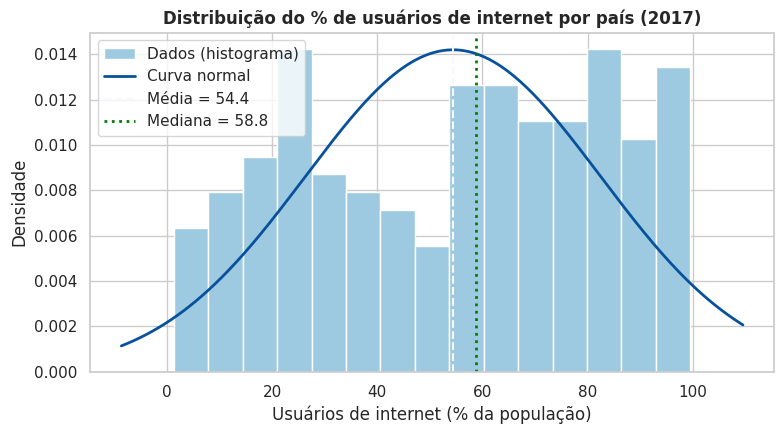

In [12]:
x = base["internet_pct"]
mu, sigma, mediana = x.mean(), x.std(ddof=0), x.median()

# a) P(X < média)   |   b) P(X > mediana)
p_a = prob_normal_menor_que(mu, mu, sigma)
p_b = 1 - prob_normal_menor_que(mediana, mu, sigma)

print(f"Média = {mu:.4f} | Mediana = {mediana:.4f} | Desvio padrão = {sigma:.4f}")
print(f"Assimetria = {x.skew():.3f} | Curtose = {x.kurt():.3f} (0 e 0 seriam uma normal perfeita)\n")
print(f"a) P(X < média)   = {p_a:.4f} = {p_a:.2%}  ->  {classificar_evento(p_a)}")
print(f"b) P(X > mediana) = {p_b:.4f} = {p_b:.2%}  ->  {classificar_evento(p_b)}")


# Histograma dos dados com a curva normal correspondente
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(x, bins=15, density=True, color="#9ecae1", edgecolor="white", label="Dados (histograma)")
eixo_x = np.linspace(x.min() - 10, x.max() + 10, 300)
ax.plot(eixo_x, densidade_normal(eixo_x, mu, sigma), color="#08519c", lw=2, label="Curva normal")
ax.axvline(mu, color=COR_DESTAQUE, ls="--", label=f"Média = {mu:.1f}")
ax.axvline(mediana, color="green", ls=":", lw=2, label=f"Mediana = {mediana:.1f}")
configurar_eixos(ax, "Distribuição do % de usuários de internet por país (2017)","Usuários de internet (% da população)", "Densidade")
ax.legend()
plt.tight_layout()
plt.show()


## 3. TESTES DE HIPÓTESES PARA A MÉDIA (teste Z)
## Média de referência = média de todos os países | Desvio padrão de referência = desvio padrão dos dados

In [15]:
mu0, sigma_ref = mu, sigma

res_a = teste_z_unilateral(x, mu0, sigma_ref, n_amostra=20, alfa=0.06, cauda="menor")
res_b = teste_z_unilateral(x, mu0, sigma_ref, n_amostra=25, alfa=0.09, cauda="maior")

exibir_teste_z(res_a, "a) média MENOR que a de referência | alfa = 6% | n = 20")
print()
exibir_teste_z(res_b, "b) média MAIOR que a de referência | alfa = 9% | n = 25")

=== a) média MENOR que a de referência | alfa = 6% | n = 20 ===
H0: μ = 54.40   |   H1: μ < 54.40
n = 20 | nível de significância = 6% | média da amostra = 58.6391
Z calculado = 0.6754 | Z crítico = -1.5548 | p-valor = 0.7503
DECISÃO: NÃO REJEITA H0

=== b) média MAIOR que a de referência | alfa = 9% | n = 25 ===
H0: μ = 54.40   |   H1: μ > 54.40
n = 25 | nível de significância = 9% | média da amostra = 57.0564
Z calculado = 0.4733 | Z crítico = 1.3408 | p-valor = 0.3180
DECISÃO: NÃO REJEITA H0


### 4. ANÁLISE BIVARIADA – X: banda larga | Y: usuários de internet (%)

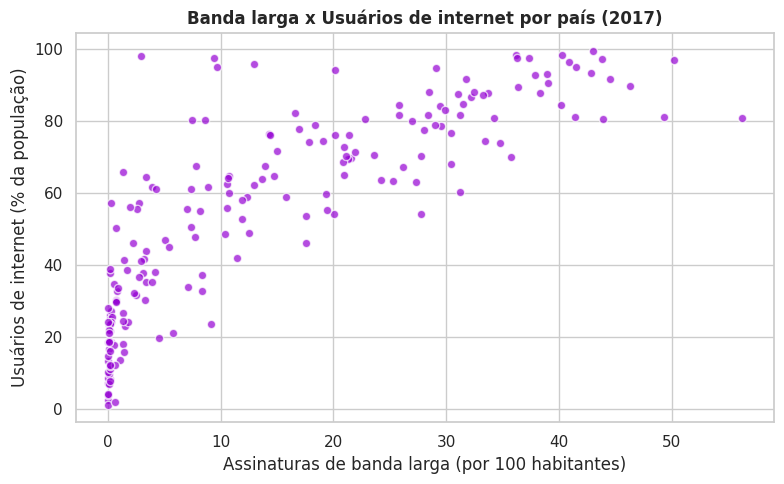

Covariância = 338.7053
Correlação de Pearson (r) = 0.8230


In [19]:
X1 = base["banda_larga"]
Y = base["internet_pct"]

# a) Gráfico de dispersão
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X1, Y, alpha=0.7, color=COR_PRINCIPAL, edgecolor="white")
configurar_eixos(ax, "Banda larga x Usuários de internet por país (2017)", "Assinaturas de banda larga (por 100 habitantes)", "Usuários de internet (% da população)")
plt.tight_layout()
plt.show()

# b) Covariância e correlação linear de Pearson
cov_xy = X1.cov(Y)
r = X1.corr(Y)
print(f"Covariância = {cov_xy:.4f}")
print(f"Correlação de Pearson (r) = {r:.4f}")


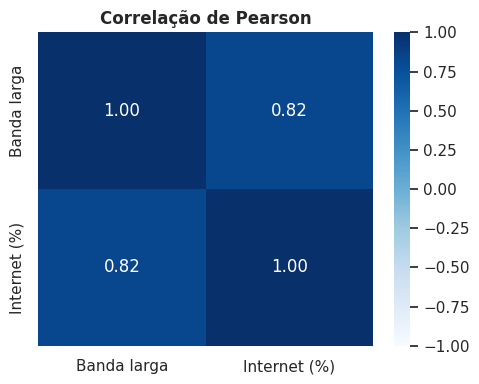

In [18]:
# c) Gráfico da correlação linear de Pearson
mapa_calor_correlacao(base[["banda_larga", "internet_pct"]].corr(),["Banda larga", "Internet (%)"], "Correlação de Pearson", (5, 4))

Equação: Internet(%) = 31.3851 + 1.5858 x Banda_larga


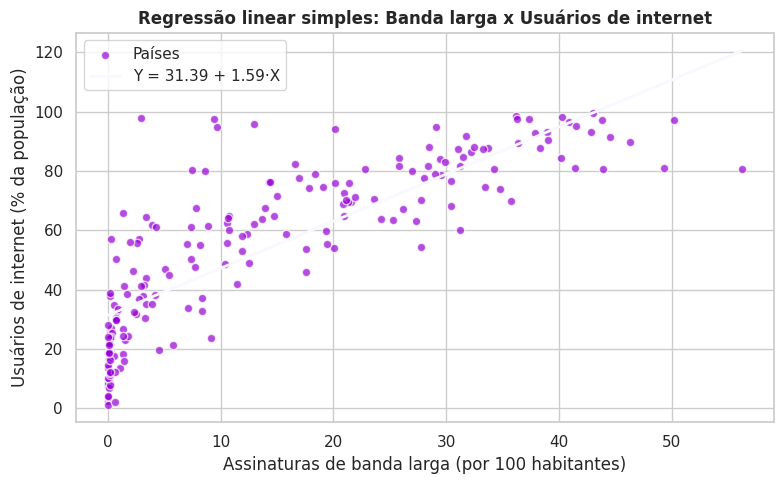


H0: o modelo NÃO é significativo  |  H1: o modelo é significativo
R² = 0.6774
F calculado = 401.02 | F crítico (5%) = 3.88 | p-valor < 0.000001
DECISÃO: REJEITA H0 (modelo significativo)
Com 20 assinaturas/100 hab., o % de usuários de internet previsto é 63.10%


In [25]:
# d) Reta da regressão linear simples e equação
modelo1 = ajustar_regressao_linear(base[["banda_larga"]], Y)
b0, b1 = modelo1["coef"]
print(f"Equação: Internet(%) = {b0:.4f} + {b1:.4f} x Banda_larga")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X1, Y, alpha=0.7, color=COR_PRINCIPAL, edgecolor="white", label="Países")
linha_x = np.linspace(X1.min(), X1.max(), 100)
ax.plot(linha_x, b0 + b1 * linha_x, color=COR_DESTAQUE, lw=2, label=f"Y = {b0:.2f} + {b1:.2f}·X")
configurar_eixos(ax, "Regressão linear simples: Banda larga x Usuários de internet","Assinaturas de banda larga (por 100 habitantes)", "Usuários de internet (% da população)")
ax.legend()
plt.tight_layout()
plt.show()

# e) Adequação do modelo: R² e teste F
r2_1, F1 = modelo1["r2"], modelo1["F"]
teste_f1 = teste_f_por_simulacao(F1, modelo1["gl_num"], modelo1["gl_den"])
F1_crit, pF1 = teste_f1["F_critico"], teste_f1["p_valor"]

print("\nH0: o modelo NÃO é significativo  |  H1: o modelo é significativo")
print(f"R² = {r2_1:.4f}")
print(f"F calculado = {F1:.2f} | F crítico (5%) = {F1_crit:.2f} | p-valor {formatar_p(pF1, teste_f1['resolucao'])}")
print("DECISÃO:", "REJEITA H0 (modelo significativo)" if F1 > F1_crit else "NÃO REJEITA H0\n")

# f) Previsão: país com 20 assinaturas de banda larga por 100 habitantes
banda_nova = 20
previsao1 = b0 + b1 * banda_nova
print(f"Com {banda_nova} assinaturas/100 hab., o % de usuários de internet previsto é {previsao1:.2f}%")


## 5. REGRESSÃO LINEAR MÚLTIPLA – Y: internet (%) | X1: celular | X2: banda larga


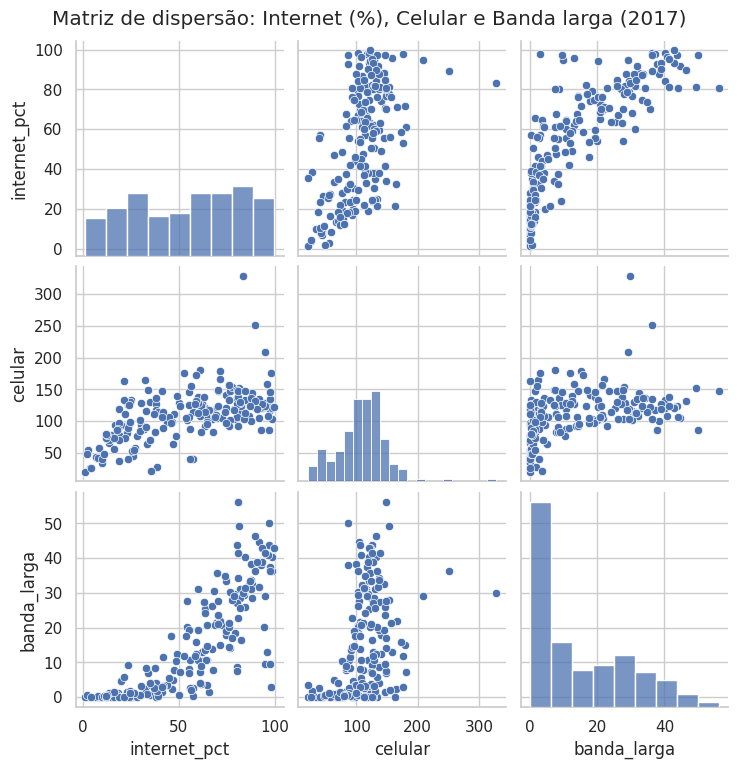

MATRIZ DE COVARIÂNCIA
              internet_pct   celular  banda_larga
internet_pct       792.961   651.199      338.705
celular            651.199  1606.526      252.435
banda_larga        338.705   252.435      213.581

MATRIZ DE CORRELAÇÃO DE PEARSON
              internet_pct  celular  banda_larga
internet_pct         1.000    0.577        0.823
celular              0.577    1.000        0.431
banda_larga          0.823    0.431        1.000


In [27]:
vars_m = ["internet_pct", "celular", "banda_larga"]

# a) Gráficos de dispersão (todas as variáveis, duas a duas)
g = sns.pairplot(base[vars_m])
g.figure.suptitle("Matriz de dispersão: Internet (%), Celular e Banda larga (2017)", y=1.02)
plt.show()


# b) Matriz de covariância e matriz de correlação de Pearson
cov_m = base[vars_m].cov()
corr_m = base[vars_m].corr()
print("MATRIZ DE COVARIÂNCIA")
print(cov_m.round(3))
print("\nMATRIZ DE CORRELAÇÃO DE PEARSON")
print(corr_m.round(3))

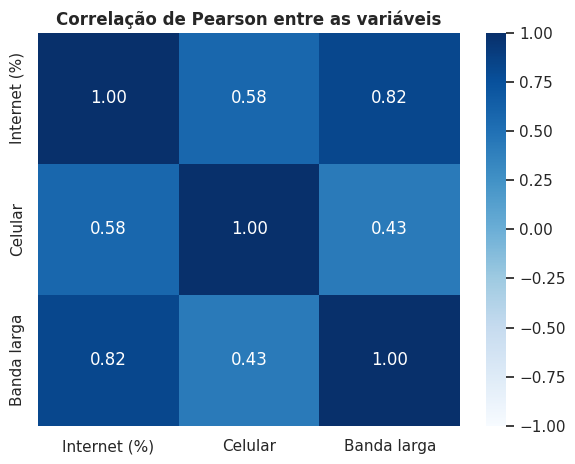

Equação: Internet(%) = 13.8368 + 0.1918 x Celular + 1.3592 x Banda_larga

             coeficiente
Intercepto       13.8368
Celular           0.1918
Banda larga       1.3592
H0: o modelo NÃO é significativo  |  H1: o modelo é significativo
R² = 0.7380 | R² ajustado = 0.7353
F calculado = 267.66 | F crítico (5%) = 3.04 | p-valor < 0.000001
DECISÃO: REJEITA H0 (modelo significativo)


In [28]:
# c) Gráfico da correlação linear de Pearson
mapa_calor_correlacao(corr_m, ["Internet (%)", "Celular", "Banda larga"],
                      "Correlação de Pearson entre as variáveis", (6, 4.8))


# d) Equação da regressão linear múltipla
modelo2 = ajustar_regressao_linear(base[["celular", "banda_larga"]], Y)
a0, a_cel, a_ban = modelo2["coef"]
print(f"Equação: Internet(%) = {a0:.4f} + {a_cel:.4f} x Celular + {a_ban:.4f} x Banda_larga")

tab_coef = pd.DataFrame({"coeficiente": [a0, a_cel, a_ban]}, index=["Intercepto", "Celular", "Banda larga"])
print()
print(tab_coef.round(4))


# e) Adequação do modelo: R², R² ajustado e teste F
r2_2, r2aj_2, F2 = modelo2["r2"], modelo2["r2_ajustado"], modelo2["F"]
teste_f2 = teste_f_por_simulacao(F2, modelo2["gl_num"], modelo2["gl_den"])
F2_crit, pF2 = teste_f2["F_critico"], teste_f2["p_valor"]

print("H0: o modelo NÃO é significativo  |  H1: o modelo é significativo")
print(f"R² = {r2_2:.4f} | R² ajustado = {r2aj_2:.4f}")
print(f"F calculado = {F2:.2f} | F crítico (5%) = {F2_crit:.2f} | p-valor {formatar_p(pF2, teste_f2['resolucao'])}")
print("DECISÃO:", "REJEITA H0 (modelo significativo)" if F2 > F2_crit else "NÃO REJEITA H0")

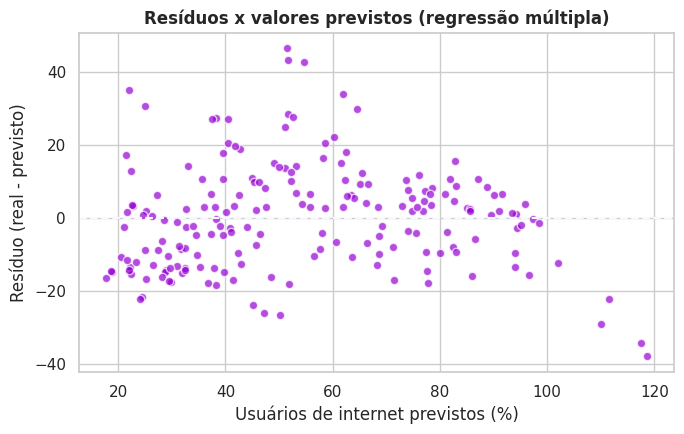

Celular = 110 e Banda larga = 15  ->  Internet prevista = 55.32%


In [29]:
# Gráfico dos resíduos (erro = real - previsto)
Yhat2 = modelo2["previsto"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Yhat2, Y - Yhat2, alpha=0.7, color=COR_PRINCIPAL, edgecolor="white")
ax.axhline(0, color=COR_DESTAQUE, ls="--")
configurar_eixos(ax, "Resíduos x valores previstos (regressão múltipla)",
                 "Usuários de internet previstos (%)", "Resíduo (real - previsto)")
plt.tight_layout()
plt.show()


# f) Previsão com 2 variáveis explicativas: celular = 110 e banda larga = 15 (por 100 habitantes)
previsao2 = a0 + a_cel * 110 + a_ban * 15
print(f"Celular = 110 e Banda larga = 15  ->  Internet prevista = {previsao2:.2f}%")

# 6. REGRESSÃO LOGÍSTICA BINÁRIA
# Resposta: acesso_alto = 1 se pelo menos 50% da população usa internet, senão 0

acesso_alto
acesso alto (1)     112
acesso baixo (0)     81
Name: count, dtype: int64

Treino: 135 países | Teste: 58 países

ln( p / (1 - p) ) = -4.0916 + 0.0194 x Celular + 0.3010 x Banda_larga
p = 1 / (1 + e^-(c0 + c1·Celular + c2·Banda_larga))
Razão de chances (odds ratio): Celular = 1.0196 | Banda larga = 1.3512
Matriz de confusão (linhas = real, colunas = previsto):
[[20  4]
 [ 2 32]]

Acurácia no teste  = 0.8966
Acurácia no treino = 0.8963
Acurácia de referência (classe mais comum) = 0.5862

                  precision    recall  f1-score   support

Acesso baixo (0)       0.91      0.83      0.87        24
 Acesso alto (1)       0.89      0.94      0.91        34

        accuracy                           0.90        58
       macro avg       0.90      0.89      0.89        58
    weighted avg       0.90      0.90      0.90        58



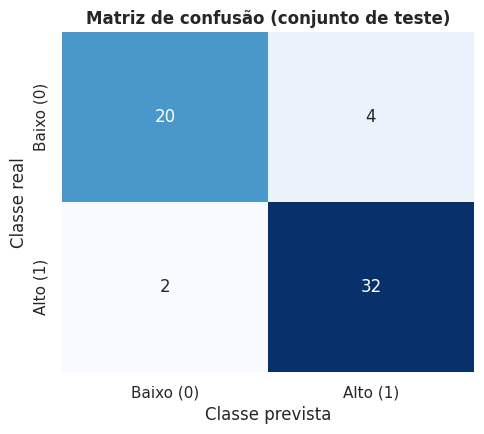

        celular  banda_larga  prob_acesso_alto   classe_prevista
País A      120           10            0.7765   Acesso alto (1)
País B       60            1            0.0674  Acesso baixo (0)


,Acurácia,Precisão,Recall,F1
Modelo,,,,
Regressão logística,0.8966,0.8889,0.9412,0.9143
KNN (k = 5),0.9310,0.9167,0.9706,0.9429
Árvore de decisão (profundidade 3),0.9138,0.8919,0.9706,0.9296


In [30]:
base["acesso_alto"] = (base["internet_pct"] >= LIMIAR_ACESSO_ALTO).astype(int)
print(base["acesso_alto"].value_counts().rename({1: "acesso alto (1)", 0: "acesso baixo (0)"}))

Xl = base[["celular", "banda_larga"]]
yl = base["acesso_alto"]

# 70% dos países para treinar o modelo e 30% para testá-lo
X_tr, X_te, y_tr, y_te = train_test_split(Xl, yl, test_size=0.30, random_state=SEMENTE, stratify=yl)
print(f"\nTreino: {len(X_tr)} países | Teste: {len(X_te)} países")

# a) Equação da regressão logística
logit = ajustar_regressao_logistica(X_tr, y_tr)
c0 = logit["intercepto"]
c_cel, c_ban = logit["coef"]
print()
print(f"ln( p / (1 - p) ) = {c0:.4f} + {c_cel:.4f} x Celular + {c_ban:.4f} x Banda_larga")
print("p = 1 / (1 + e^-(c0 + c1·Celular + c2·Banda_larga))")
print(f"Razão de chances (odds ratio): Celular = {np.exp(c_cel):.4f} | Banda larga = {np.exp(c_ban):.4f}")


# b) Matriz de confusão e acurácia (países de TESTE, que o modelo nunca viu)
y_pred = (probabilidade_logistica(logit, X_te) >= 0.5).astype(int)
mc = confusion_matrix(y_te, y_pred)
# verdadeiro neg., falso pos., falso neg., verdadeiro pos.
tn, fp, fn, tp = mc.ravel()

acc_te = accuracy_score(y_te, y_pred)
acc_tr = accuracy_score(y_tr, (probabilidade_logistica(logit, X_tr) >= 0.5).astype(int))
 # acurácia de "chutar" sempre a classe mais comum
acc_base = max(y_te.mean(), 1 - y_te.mean())

print("Matriz de confusão (linhas = real, colunas = previsto):")
print(mc)
print(f"\nAcurácia no teste  = {acc_te:.4f}")
print(f"Acurácia no treino = {acc_tr:.4f}")
print(f"Acurácia de referência (classe mais comum) = {acc_base:.4f}")
print("\n" + classification_report(y_te, y_pred, target_names=["Acesso baixo (0)", "Acesso alto (1)"]))

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(mc, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,xticklabels=["Baixo (0)", "Alto (1)"], yticklabels=["Baixo (0)", "Alto (1)"])
configurar_eixos(ax, "Matriz de confusão (conjunto de teste)", "Classe prevista", "Classe real")
plt.tight_layout()
plt.show()


# c) Classificação de novos países com 2 variáveis explicativas
novos = pd.DataFrame({"celular": [120, 60], "banda_larga": [10, 1]}, index=["País A", "País B"])
prob = probabilidade_logistica(logit, novos)
novos["prob_acesso_alto"] = prob.round(4)
novos["classe_prevista"] = np.where(prob >= 0.5, "Acesso alto (1)", "Acesso baixo (0)")
print(novos)


# Comparação com outros classificadores (mesma divisão treino/teste)
# O KNN depende de distâncias: padronizamos as variáveis com a média e o desvio do TREINO.
media_tr, desvio_tr = X_tr.mean(), X_tr.std()
X_tr_pad = (X_tr - media_tr) / desvio_tr
X_te_pad = (X_te - media_tr) / desvio_tr

knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_pad, y_tr)
arvore = DecisionTreeClassifier(max_depth=3, random_state=SEMENTE).fit(X_tr, y_tr)

comparacao = pd.DataFrame([avaliar_classificador("Regressão logística", y_te, y_pred),avaliar_classificador("KNN (k = 5)", y_te, knn.predict(X_te_pad)),avaliar_classificador("Árvore de decisão (profundidade 3)", y_te, arvore.predict(X_te)),]).set_index("Modelo")
comparacao.round(4)

## 7. Conclusões e limitações
**Principais resultados:**

- A banda larga é a variável mais fortemente associada ao acesso à internet (r = 0,82); sozinha explica ≈ 68% da variação entre países.
- Somando celular e banda larga o poder explicativo sobe para ≈ 74%, mostrando que as duas infraestruturas se complementam.
- Para o CitizenTech, priorizar banda larga fixa em comunidades pouco conectadas tende a trazer mais ganho de inclusão do que apenas ampliar o número de linhas de celular.
- O modelo logístico classifica corretamente ≈ 90% dos países como de acesso alto ou baixo, podendo servir como triagem inicial de onde a exclusão digital é mais provável.

**Limitações:**

- Os dados são por país (nível agregado) e de um único ano (2017). Não descrevem cidades, zonas rurais ou comunidades específicas; conclusões sobre o território interno de um país exigiriam dados locais.
- Foram excluídos 11 países que tinham valor 0 (dado ausente) em alguma variável, o que pode enviesar a amostra para países que reportam melhor seus dados.
- Associação não é causalidade: renda, educação, urbanização e preço dos planos não estão no modelo e podem influenciar todas as variáveis.
- A normalidade foi assumida conforme o enunciado, mas o percentual de internautas é limitado entre 0 e 100%; a aproximação é imperfeita.
- Os testes de hipóteses usam uma amostra aleatória (semente 42); outra amostra poderia levar a conclusões diferentes, o que é natural em testes com n pequeno.
- Celular pode passar de 100 por 100 habitantes porque uma pessoa pode ter mais de um chip, o que dificulta a interpretação direta.
- O limiar de 50% na regressão logística é uma escolha do grupo; outro limiar alteraria a matriz de confusão.